In [3023]:
#Loading the data
import pandas as pd # Importing the pandas librabry
df = pd.read_csv('./finanical_report_2018.csv', na_values = ["n/a"])
df.info()
                 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3845 entries, 0 to 3844
Data columns (total 13 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Stock Code                           3845 non-null   int64  
 1   Market Value of Equity               3845 non-null   float64
 2   Total Market Value                   3845 non-null   float64
 3   Stock Return                         3817 non-null   float64
 4   Total Investment Expenditure         3845 non-null   float64
 5   Amortization and Depreciation        3845 non-null   float64
 6   Book Value                           3845 non-null   float64
 7   Operating Income after Depreciation  3845 non-null   float64
 8   Annual Dividends                     3845 non-null   float64
 9   Leverage                             3845 non-null   float64
 10  Cash                                 3845 non-null   float64
 11  Age                           

In [3025]:
df["Size"] = pd.to_numeric(df["Size"], errors = 'coerce') # We see that the data type for 'Size' is 'Object', meaning that it probarbly has a non_numeric value , thus we must convert all values to a numeric value, so we can check for any dirty data
print(df.dtypes)

Stock Code                               int64
Market Value of Equity                 float64
Total Market Value                     float64
Stock Return                           float64
Total Investment Expenditure           float64
Amortization and Depreciation          float64
Book Value                             float64
Operating Income after Depreciation    float64
Annual Dividends                       float64
Leverage                               float64
Cash                                   float64
Age                                    float64
Size                                   float64
dtype: object


In [3027]:
null_masks = df.isnull().sum() # Returns a mask list showing any null values in any of the coloumns
null_masks

Stock Code                              0
Market Value of Equity                  0
Total Market Value                      0
Stock Return                           28
Total Investment Expenditure            0
Amortization and Depreciation           0
Book Value                              0
Operating Income after Depreciation     0
Annual Dividends                        0
Leverage                                0
Cash                                    0
Age                                     0
Size                                    1
dtype: int64

In [3029]:
# Identifying missing/ wrong values in different features relating to that stock code
x = 0
for stock_code in df.index:
    for feature in df.columns:
        
        if pd.isna(df.at[stock_code, feature]) == True:
            print(f"Stock Code: {stock_code}, feature: {feature} ")
            x = x + 1
print(f"Total missing values= {x} ")
#1.A

Stock Code: 316, feature: Stock Return 
Stock Code: 779, feature: Stock Return 
Stock Code: 781, feature: Stock Return 
Stock Code: 1124, feature: Size 
Stock Code: 1749, feature: Stock Return 
Stock Code: 1903, feature: Stock Return 
Stock Code: 2059, feature: Stock Return 
Stock Code: 2681, feature: Stock Return 
Stock Code: 2701, feature: Stock Return 
Stock Code: 2767, feature: Stock Return 
Stock Code: 2792, feature: Stock Return 
Stock Code: 3024, feature: Stock Return 
Stock Code: 3071, feature: Stock Return 
Stock Code: 3098, feature: Stock Return 
Stock Code: 3155, feature: Stock Return 
Stock Code: 3162, feature: Stock Return 
Stock Code: 3195, feature: Stock Return 
Stock Code: 3199, feature: Stock Return 
Stock Code: 3293, feature: Stock Return 
Stock Code: 3297, feature: Stock Return 
Stock Code: 3308, feature: Stock Return 
Stock Code: 3312, feature: Stock Return 
Stock Code: 3316, feature: Stock Return 
Stock Code: 3509, feature: Stock Return 
Stock Code: 3604, feature: 

#1.B
To identify missing or wrong values, we used a method of seraching for any 'N/A / NaN ' values when loading the data. Additonally, when looking at the data types, we see that the data type for 'Size' is object, meaning there could possibly be wrong values in this column as you would expect 'float64' like the other columns. After converting all values to a numeric form within the 'Size' column, we then were able to calaculate the the total number of 'Null' values within the dataset as well as which column ( feature) the null values belong to, by making use of the 'sum feature' and ' isnull' feature. Finally, to know which 'Null value' belonged to which 'Stock code', we used a combination of 'for loops' and ' if statements' to print out the corrseponding null value to the 'stock code' of which it belongs.

In [3032]:
# Replacing all missing n/a values with the median
for stock_code in df.index:
    for feature in df.columns:
        
        if pd.isna(df.at[stock_code, feature]) == True:
            df.at[stock_code, feature] = df[feature].median()
df.to_csv('Cleaned_dataset')

To replace the null values in each of the columns for "Stock Return" and "Size", I decided to use the median value in each respective colummn to replace the missing values in that column. I chose the median value as it has a robustness to outliers. The median value is likely to be less affected by extreme values which could give a wrong representation/image of that column as a whole. The median is also a simple statistic to calculate and interpret, thus making it easier to understand as well also increasing the computational efficiency to handle large datasets. Furthermore, as the median is the middle value, this may help preserve the distribution of the data within that column, thus making the data appear more accurate/ better presentation. I did this, by first identifying the null values in each column using a for loop and then preceeding to replace that 'null value' with the median value of that column/feature. I then loaded the 'Clean data' to a csv file

In [3035]:
# Part 2 Calculating two new feature values for each company: (V/P, Investment_2018) using the 
# following equations: 
# V/P = ((1-1.24*0.12)*Book_Value +1.24*1.12* Operating_Income_after_Depreciation - 
# 1.24*0.12* Annual_Dividends)/ Market_Value_of_Equity 

# I𝒏𝒗𝒆𝒔𝒕𝒎𝒆𝒏𝒕𝟐𝟎𝟏𝟖 = 𝑇𝑜𝑡𝑎𝑙 𝐼𝑛𝑣𝑒𝑠𝑡𝑚𝑒𝑛𝑡 𝐸𝑥𝑝𝑒𝑛𝑑𝑖𝑡𝑢𝑟𝑒 − 𝐴𝑚𝑜𝑟𝑡𝑖𝑧𝑎𝑡𝑖𝑜𝑛 𝑎𝑛𝑑 𝐷𝑒𝑝𝑟𝑒𝑐𝑖𝑎𝑡𝑖𝑜n

In [3037]:
#V/P calculation
df["V/P"] = ((1-1.24*0.12)*df["Book Value"] +1.24*1.12* df["Operating Income after Depreciation"] - 1.24*0.12* df["Annual Dividends"])/ df["Market Value of Equity"]
print(df["V/P"])

0       0.357077
1       0.528143
2       0.597518
3       0.482893
4       0.481323
          ...   
3840    0.333897
3841    0.363928
3842    0.619805
3843    0.258821
3844    0.277867
Name: V/P, Length: 3845, dtype: float64


In [3039]:
#Investment_2018 Calculation
df["Investment 2018"]= df["Total Investment Expenditure"] - df["Amortization and Depreciation"]
print(df["Investment 2018"])

0          207.321400
1          662.503500
2          801.191621
3        10224.290050
4          276.220800
            ...      
3840     26398.821590
3841     64287.128500
3842     25310.405780
3843    209871.307800
3844      9538.654090
Name: Investment 2018, Length: 3845, dtype: float64


In [3041]:
df.to_csv('Cleaned_dataset.csv') # Creating a new dataset with clean data ( no missing / wrong) values

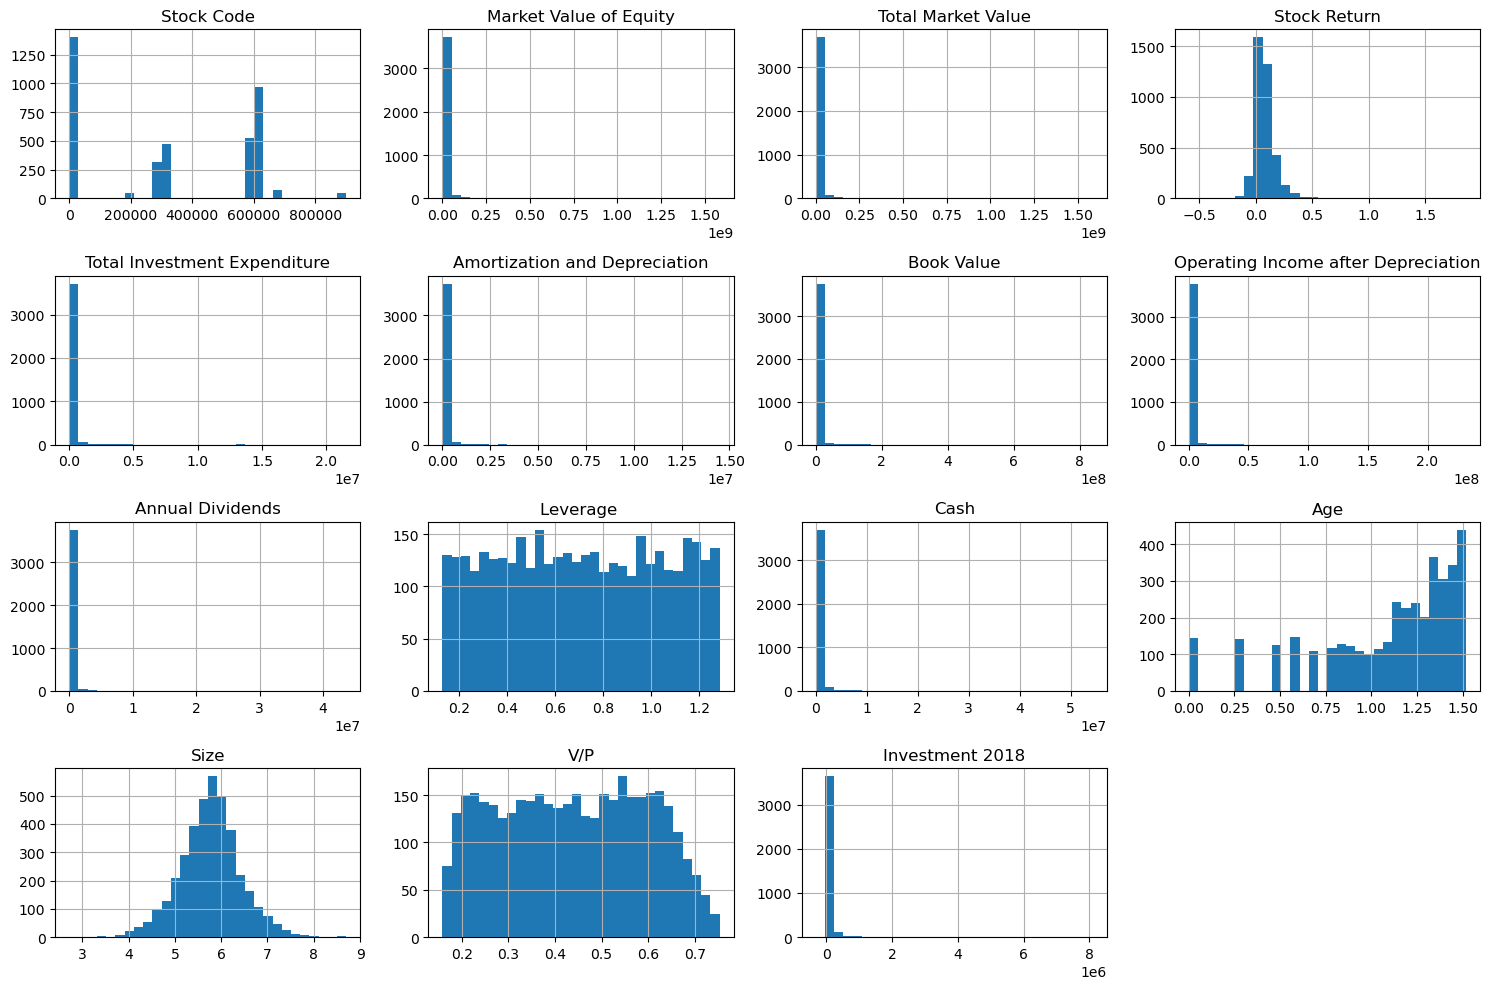

In [3043]:
# Plotting histograms to assess shape of different features
import seaborn as sns
import matplotlib.pyplot as plt

df.hist(bins = 30, figsize = (15,10))
plt.tight_layout()
plt.title(f'Histogram of {feature} ' )
plt.show()

In [3044]:
# Part 2 - Question A
# Normalizing the data
import numpy as np
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler


#df["Size"] = (df["Size"] - np.min(df["Size"]))/(np.max(df["Size"])-np.min(df["Size"])) # Using the min/max normalization method as the feature graph 'Size' appeared to have a uniform distribution.
df["Leverage "] = (df["Leverage "] - np.min(df["Leverage "]))/(np.max(df["Leverage "])-np.min(df["Leverage "]))
df["V/P"] = (df["V/P"] - np.min(df["V/P"]))/(np.max(df["V/P"])-np.min(df["V/P"]))

df['Age'] = np.sqrt(df['Age']) # The data for 'Age' and 'Market VValue of Equity was slightly skewed to the right, and contained '0' values, thus making the square-root normalization, a useful tool as it can hald values that are 0


pt = PowerTransformer(method='yeo-johnson')
df['Investment 2018'] = pt.fit_transform(df[['Investment 2018']]) # The Yeo-Johnson normalization method can help reduce skewness within models and handle both negative and positive values
df['Stock Return'] = pt.fit_transform(df[['Stock Return']])

# I have chosen to use the Logarithmic normalization method for these graphs as they are slightly skewed and contain significant outliers, also while not having values that are negative or equal to 0, thus making Logarithmc normalization possible
df['Market Value of Equity'] = np.log(df['Market Value of Equity'])
df['Total Market Value'] = np.log(df['Total Market Value'])
df['Cash'] = np.log(df['Cash'])
df['Annual Dividends'] = np.log(df['Annual Dividends'])
df['Total Investment Expenditure'] = np.log(df['Total Investment Expenditure'])
df['Amortization and Depreciation'] = np.log(df['Amortization and Depreciation'])
df['Book Value'] = np.log(df['Book Value'])
df['Operating Income after Depreciation'] = np.log(df['Operating Income after Depreciation'])

scaler = StandardScaler()
df['Size'] = scaler.fit_transform(df[['Size']])
#df['Leverage '] = scaler.fit_transform(df[['Leverage ']])
#df['V/P'] = scaler.fit_transform(df[['V/P']])
#df['Stock Return'] = scaler.fit_transform(df[['Stock Return']])
#df['Age'] = scaler.fit_transform(df[['Age']])
#df['Investment 2018'] = scaler.fit_transform(df[['Investment 2018']])

df.to_csv('Cleaned_dataset.csv')

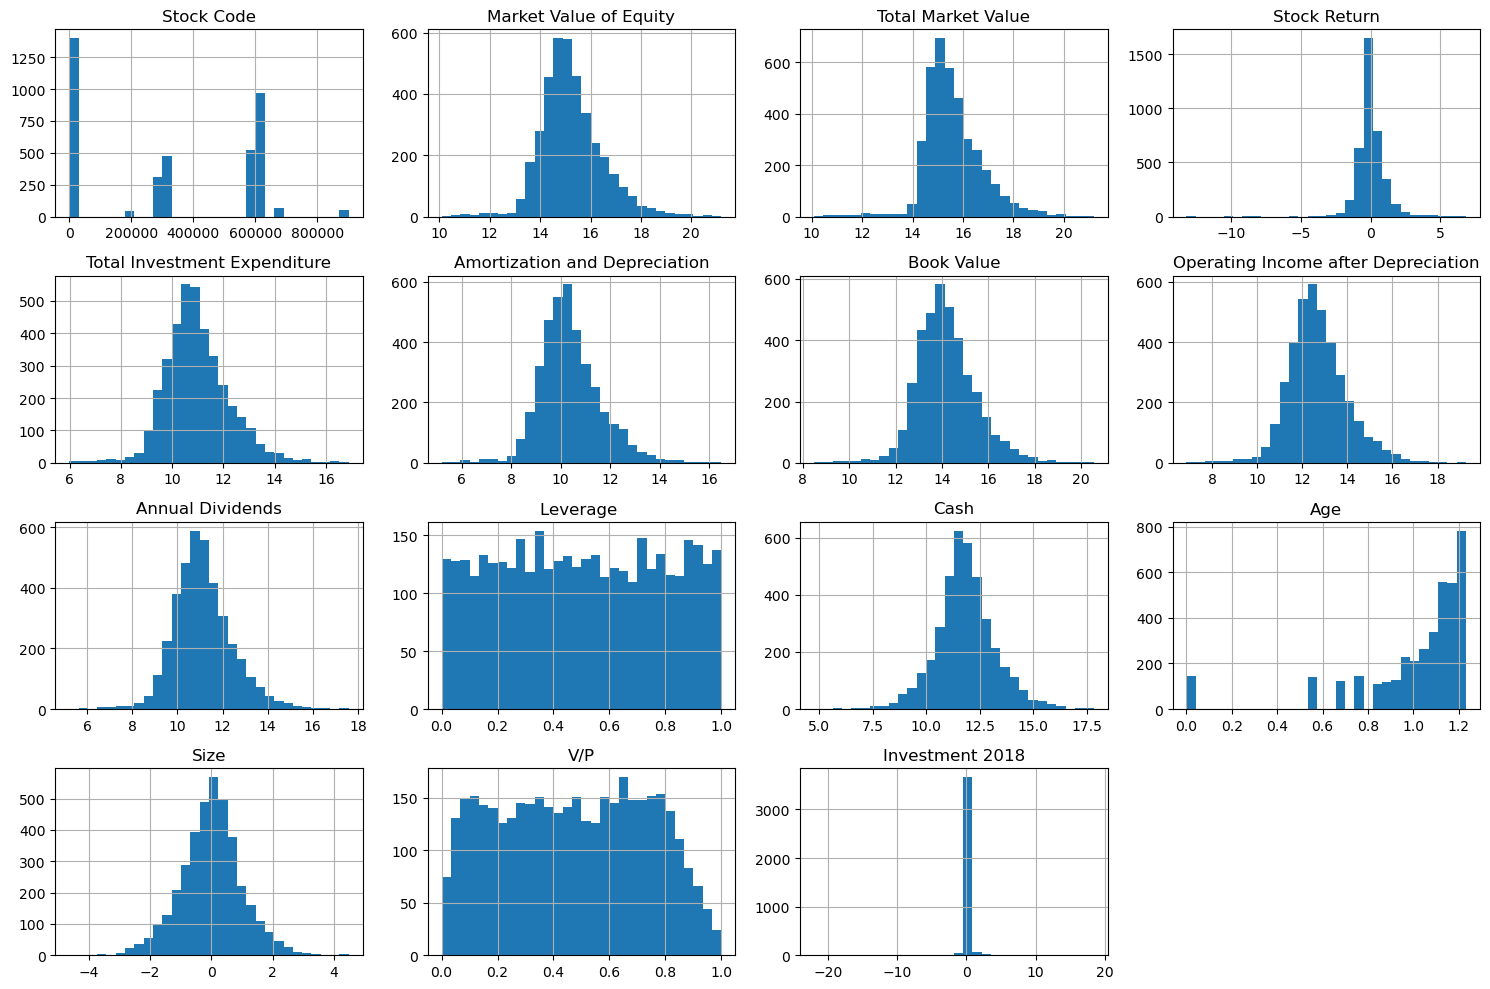

In [3045]:
# Plotting histograms/ distribution plots to assess shape of different features after normalising
import seaborn as sns
import matplotlib.pyplot as plt


df.hist(bins = 30, figsize = (15,10))
plt.tight_layout()
plt.title(f' Normalized Histogram of {feature} ' )
plt.show()
    

In [3046]:
# Checking the skewness of the graphs
numeric_columns = df.select_dtypes(include =[ np.number]).columns
for column in numeric_columns:
    skewness =  df[column].skew()
    print(f" Columns: {column}, Skewness : {skewness} ")

 Columns: Stock Code, Skewness : -0.007983630992419008 
 Columns: Market Value of Equity, Skewness : 0.5382300690321298 
 Columns: Total Market Value, Skewness : 0.45926409499214743 
 Columns: Stock Return, Skewness : -0.728764617171165 
 Columns: Total Investment Expenditure, Skewness : 0.4840025113495881 
 Columns: Amortization and Depreciation, Skewness : 0.5234051515327822 
 Columns: Book Value, Skewness : 0.430479123370767 
 Columns: Operating Income after Depreciation, Skewness : 0.4394524184550775 
 Columns: Annual Dividends, Skewness : 0.4431769109618714 
 Columns: Leverage , Skewness : 0.011917307876520292 
 Columns: Cash, Skewness : 0.10225761556846338 
 Columns: Age, Skewness : -2.3466651859895347 
 Columns: Size, Skewness : 0.013732067826786822 
 Columns: V/P, Skewness : 0.008372917958415865 
 Columns: Investment 2018, Skewness : 5.981361295266389 


In [3047]:


# I had tried using other normalization methhods for better results, however these did not have the results i had aimed for.

#from sklearn.preprocessing import QuantileTransformer
#transformer = QuantileTransformer(output_distribution='normal')
#df['Investment 2018'] = transformer.fit_transform(df[['Investment 2018']])
#df['Age'] = transformer.fit_transform(df[['Age']])
#df['Stock Return'] = transformer.fit_transform(df[['Stock Return']])


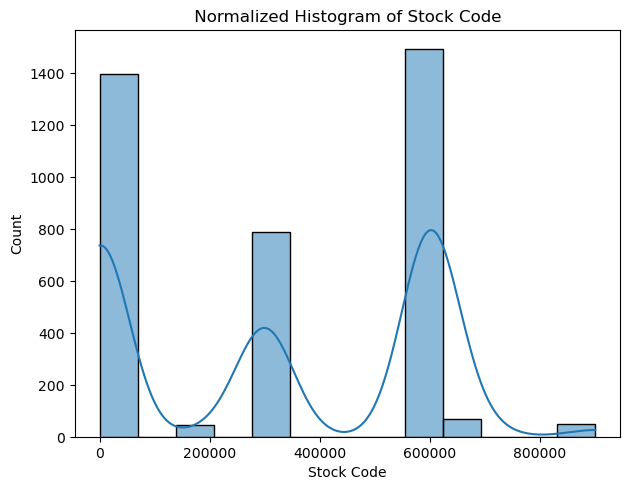

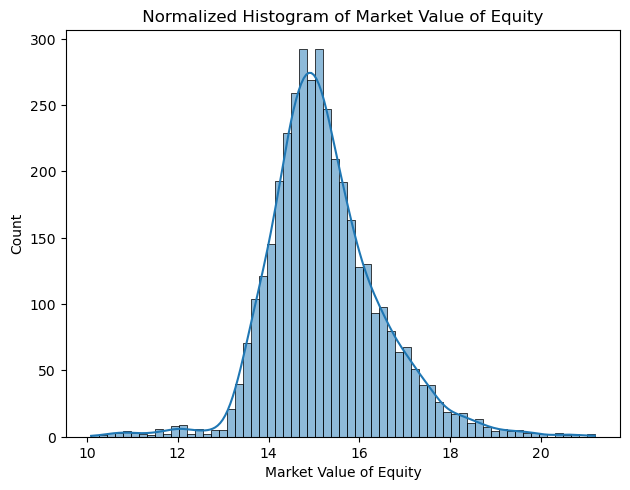

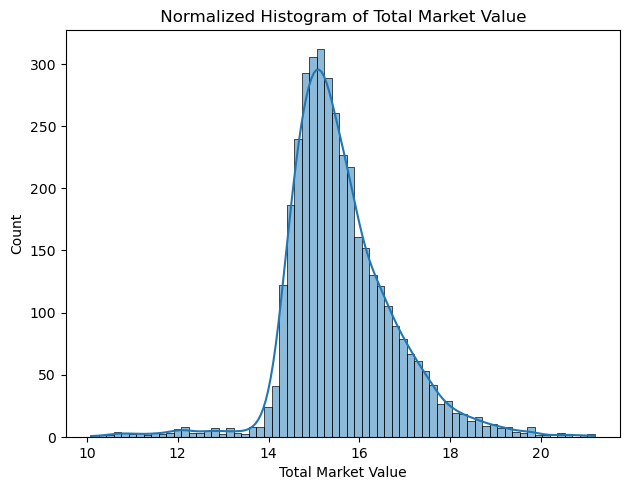

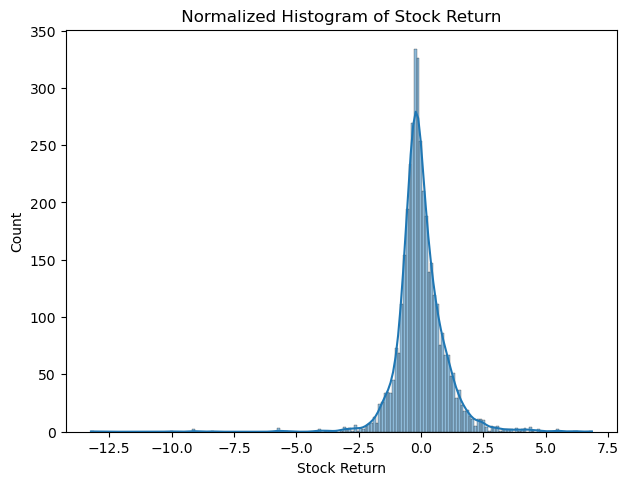

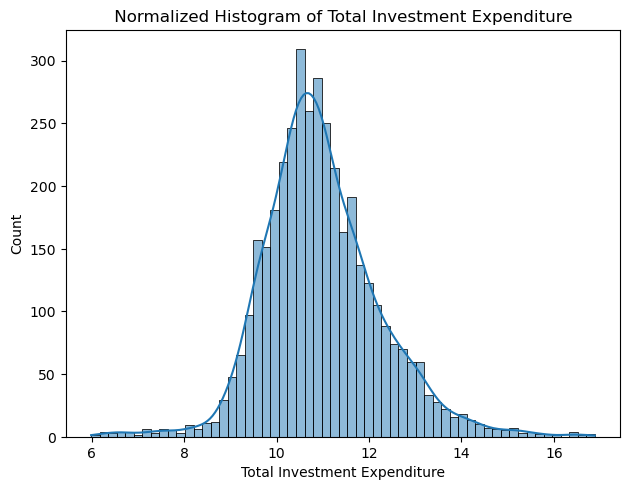

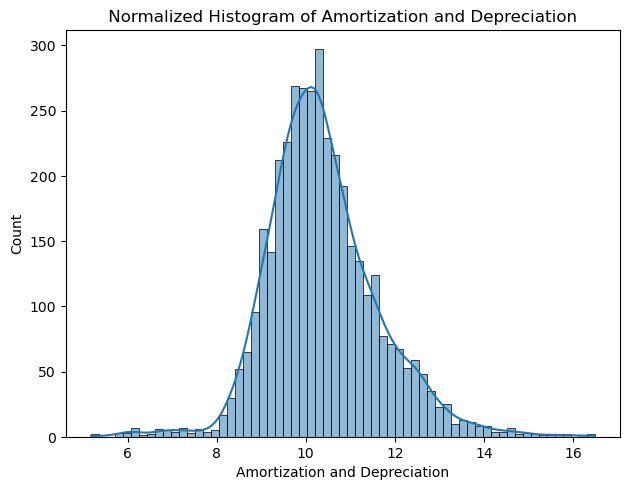

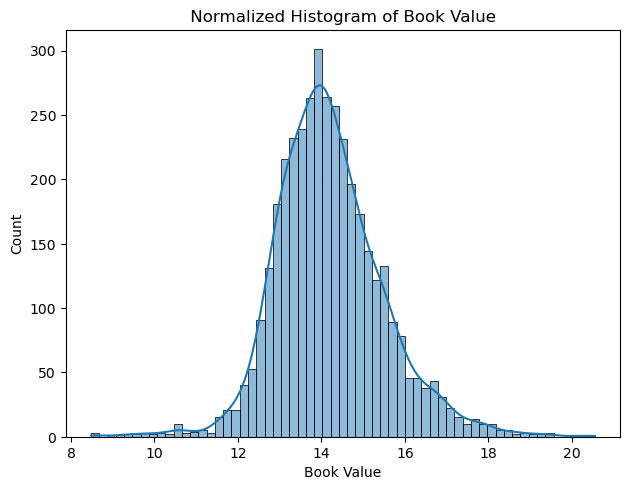

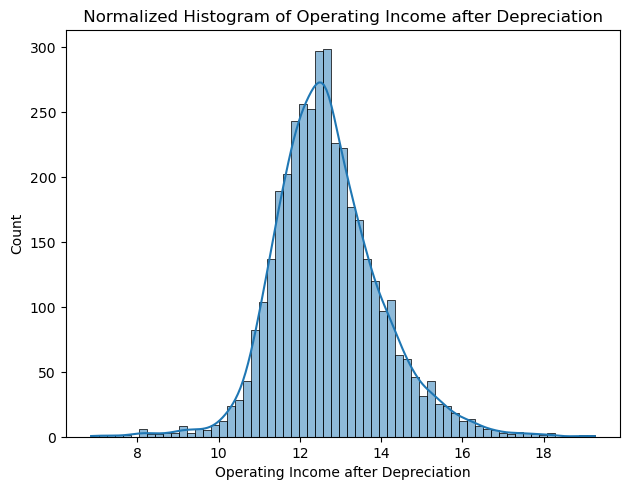

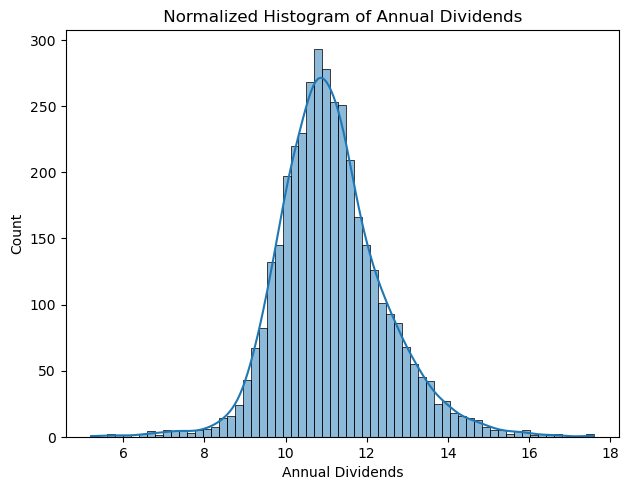

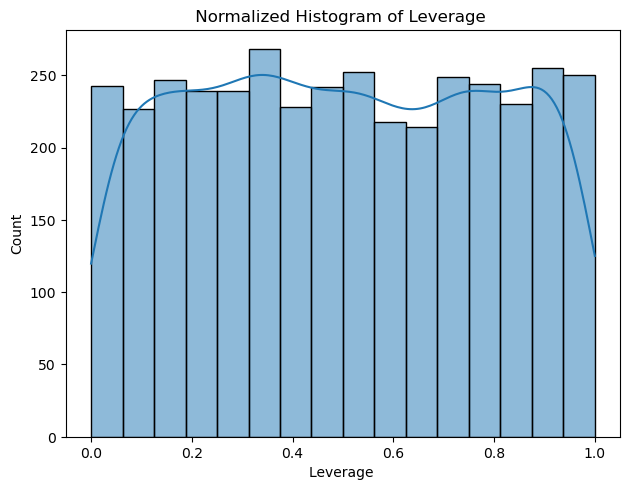

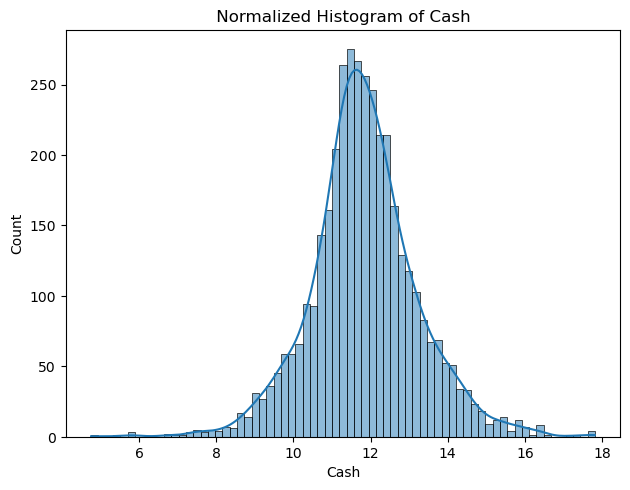

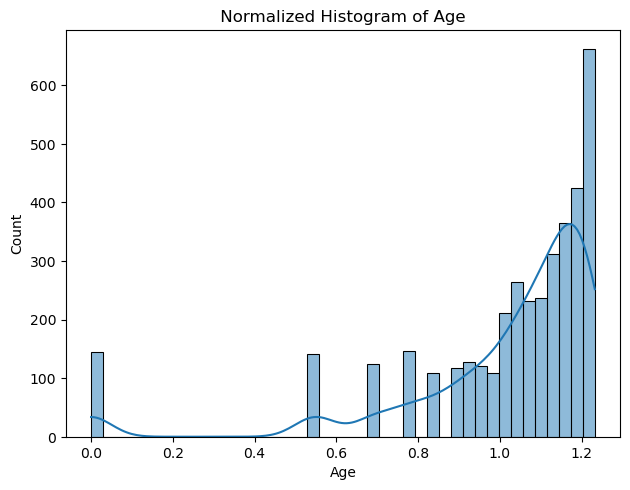

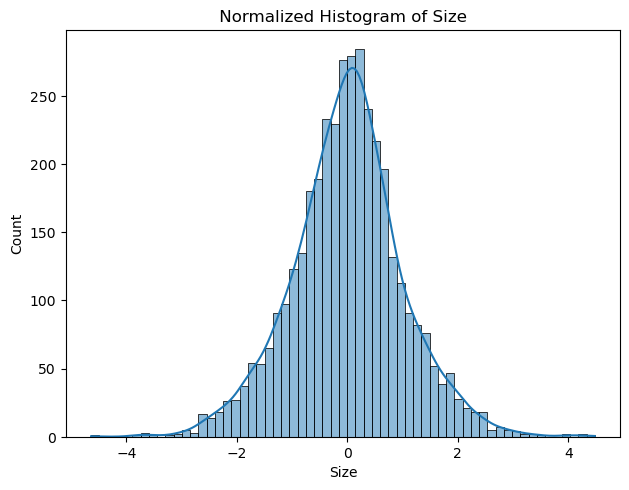

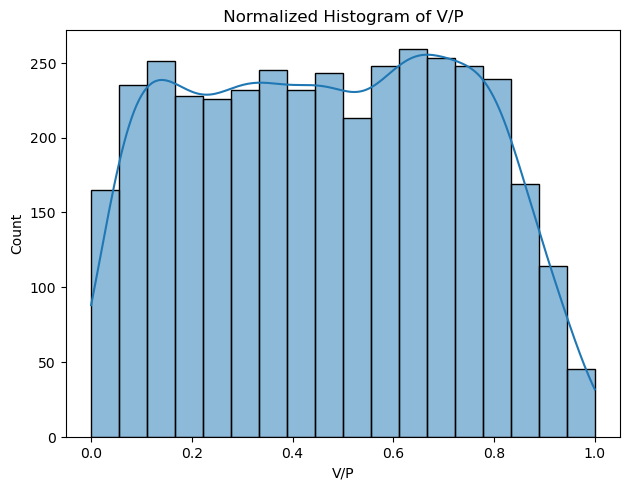

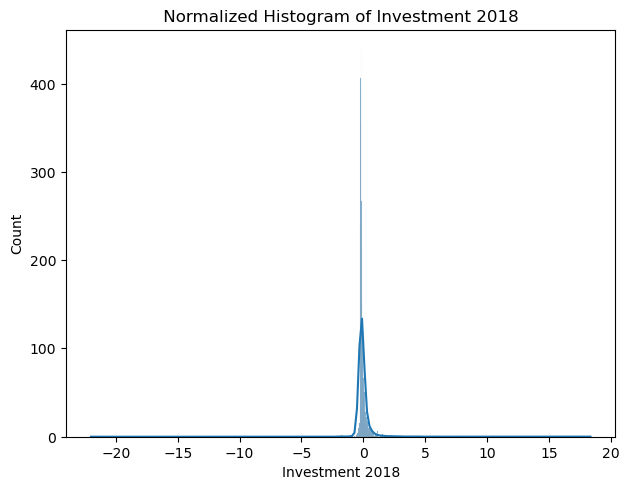

In [3050]:
#Plotting more detailed/ larger histograms/distribution plots to see the affect of normalising the data compared to the previous original histograms
import seaborn as sns
import matplotlib.pyplot as plt

for feature in df.columns:
    sns.histplot(df[feature], kde=True)
    plt.tight_layout()
    plt.title(f' Normalized Histogram of {feature} ' )
    plt.show()

Question 2 B

What methods I used and why for each Distribution plot

Firstly, i started off by plotting a hisogram for each column in the dataset. This helped me immensly as i was able to look at the data for each column and understand the shape/ skewness for each feature in the data, thus giving me an idea of how to normalise the columns based off their data types and shape. 

For each distribution plot, i chose to use a histogram as i feel this graph has many benefits. For example, the histograms, provided a clear, simplistic visualisation of the data, allowing me to see how the data was spread out and the frequency of the data within the bins. Secondly, the histograms were straightforward in enabling me to identify skewness within the data. I was easily able to spot if the data was right skewed meaning positive or left skewed meaning negative. Furthermore, through looking at the histograms, i was able to spot outliers ( data that stood out) within the graphs. Moreover, as all the graphs were histograms, this made it easier for comparison between graphs, especially when the data is affected by diferent transformations/ normalization methods. Therefore this enabled me to gain a beter overall understanding of the data and the affect of transformations.

Finally, through observing the different histograms and shape within each graph, i chose to apply a normalization method i thought would best suit that column/ feature based off the characteristics of their graph :

Firstly, I chose to apply the min/max normalization to 3 distribution plots / columns. The "Size", "Leverage" and "V/P" graphs all stood out as having a uniform distribution with no significant outliers. These characteristics are best suited a min/max normalization because the min/max method scales the data between 0 and 1, therefore meaning a more unified distribution helps to maintain this spread as well as making the data more predictable and consistent

Secondly, I had initially decided to apply the Power transformation ( Yeo-Johnson) to the Investment 2018 column as this graph showed both positive and negative values, which this normalization method is able to handle

Thirdly, most of the distribution plots represented a right skew , with no negative values.  I therefore chose to apply the Logarithmic normalization method to the majority of the columns, as they did not contain a 0 or negative values. This normalization method was good for reducing the skewness of the data and handling outliers. 









In [3066]:
# Removing Outliers using the Inter Quartile Range so the model can be more accurate

# Calculating the IQR

for feature in df.columns:
    
   Q1 = df[feature].quantile(0.25)
   Q3 = df[feature].quantile(0.75)

   IQR = Q3 - Q1

 #Defining the Upper and Lower bounds 

Lower_bound = Q1 - ( IQR * 1.5)
Upper_bound = Q3 + ( IQR * 1.5) 
                        
 #Filtering out the outliers

df = df[(df[feature] >= Lower_bound) & (df[feature] <= Upper_bound)]

df.to_csv('Cleaned_dataset.csv')


In [3068]:
# Checking the skewness of the features again after removing outliers, to see how it was impacted
numeric_columns = df.select_dtypes(include =[ np.number]).columns
for column in numeric_columns:
    skewness =  df[column].skew()
    print(f" Columns: {column}, Skewness : {skewness} ")

 Columns: Stock Code, Skewness : 0.04488679561697776 
 Columns: Market Value of Equity, Skewness : -0.50353986870532 
 Columns: Total Market Value, Skewness : -0.5394097363590333 
 Columns: Stock Return, Skewness : -0.8299232229821718 
 Columns: Total Investment Expenditure, Skewness : -0.5606130467853692 
 Columns: Amortization and Depreciation, Skewness : -0.3702410573957785 
 Columns: Book Value, Skewness : -0.4638000928216853 
 Columns: Operating Income after Depreciation, Skewness : -0.4077902422407429 
 Columns: Annual Dividends, Skewness : -0.4006809293274135 
 Columns: Leverage , Skewness : 0.013091235750452755 
 Columns: Cash, Skewness : -0.5321621420229699 
 Columns: Age, Skewness : -2.326524512125042 
 Columns: Size, Skewness : -0.06860618076997417 
 Columns: V/P, Skewness : 0.006948258392939178 
 Columns: Investment 2018, Skewness : 0.9787471187723832 


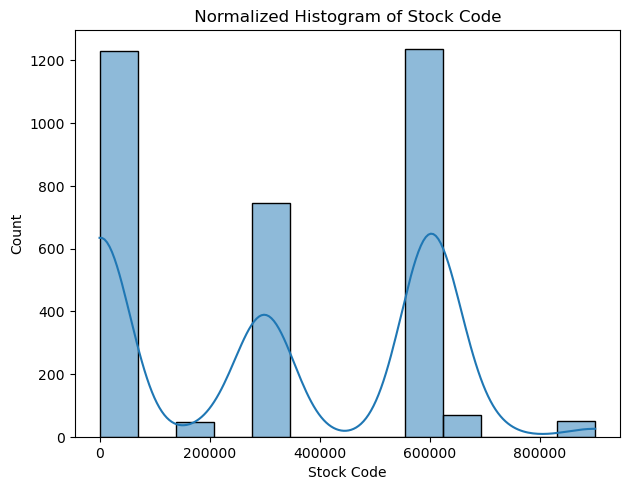

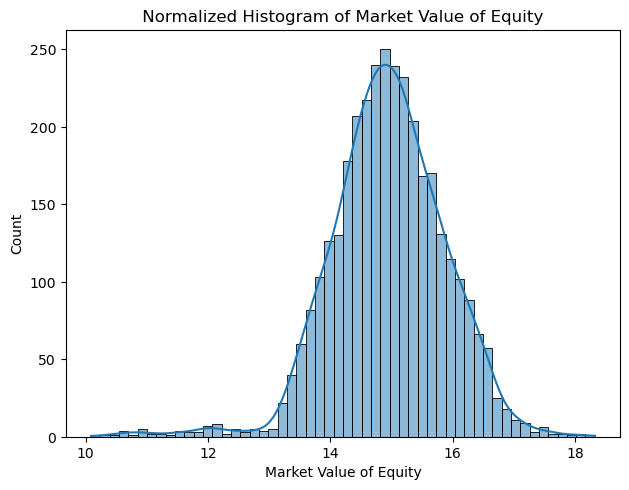

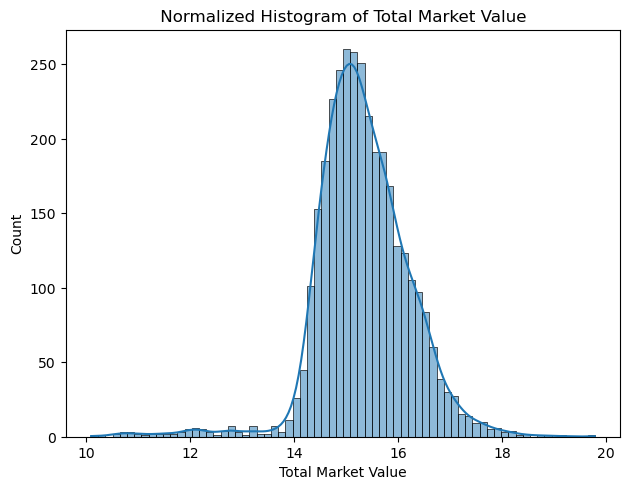

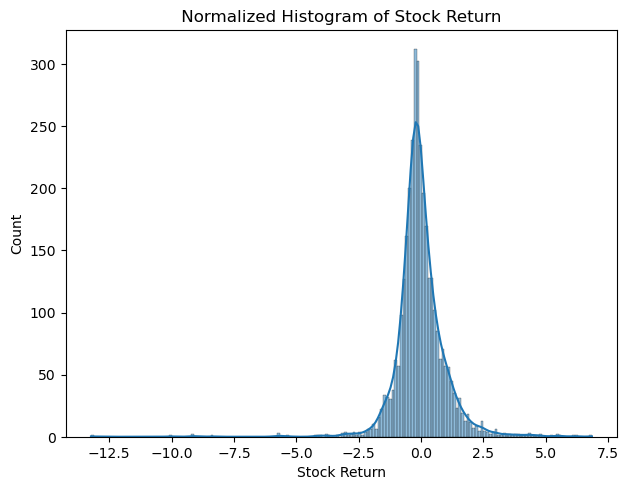

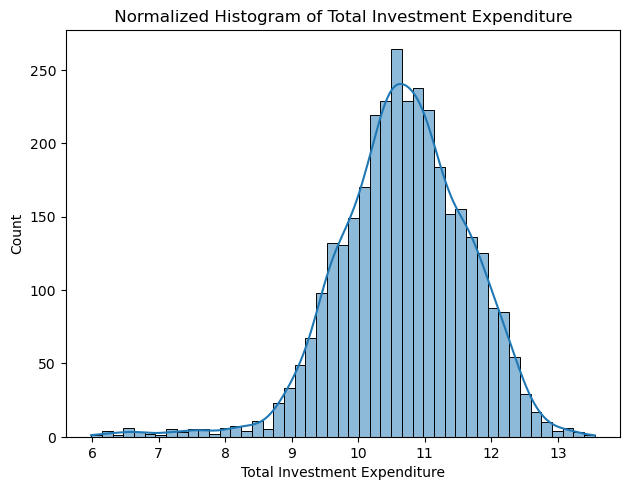

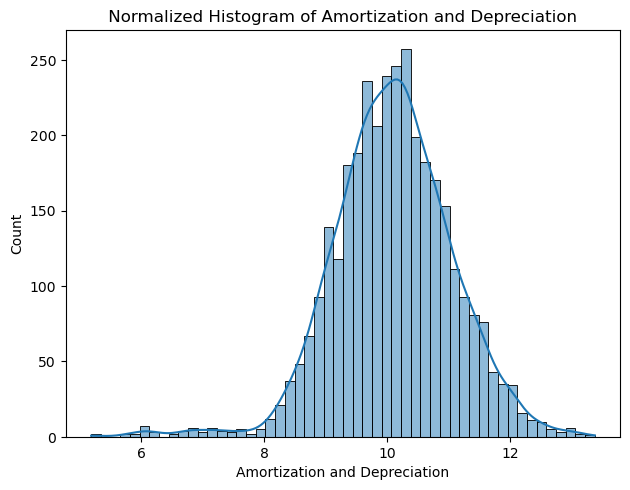

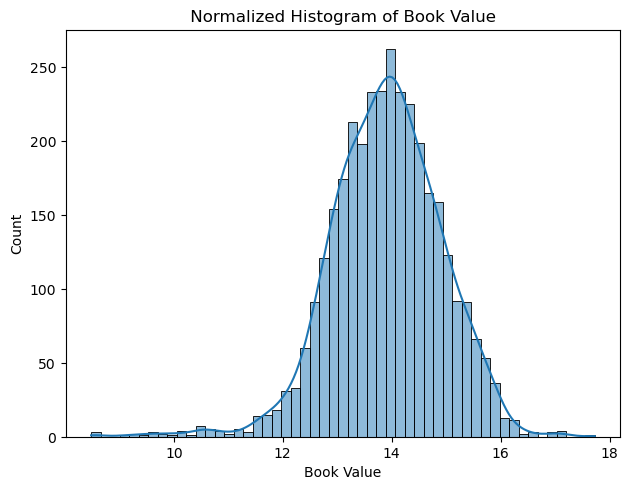

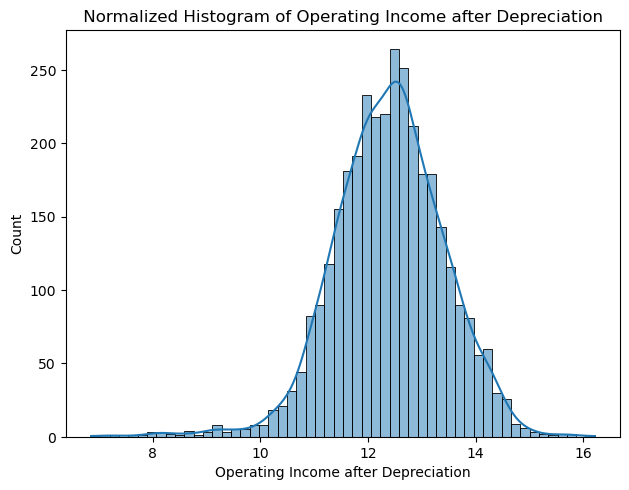

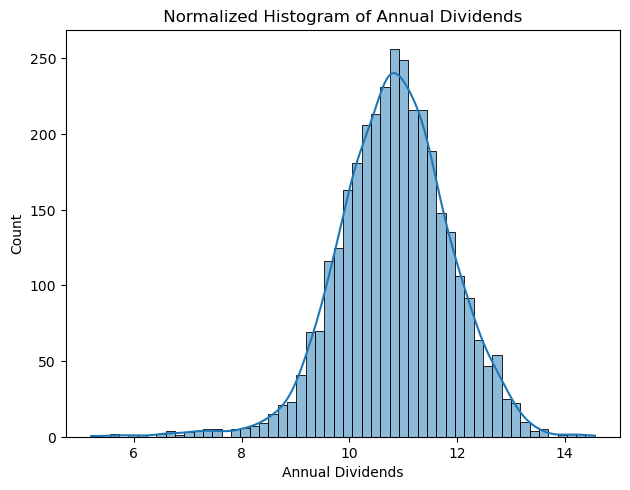

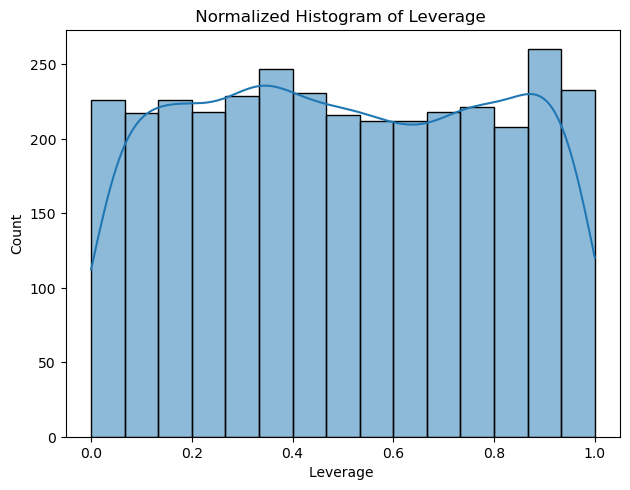

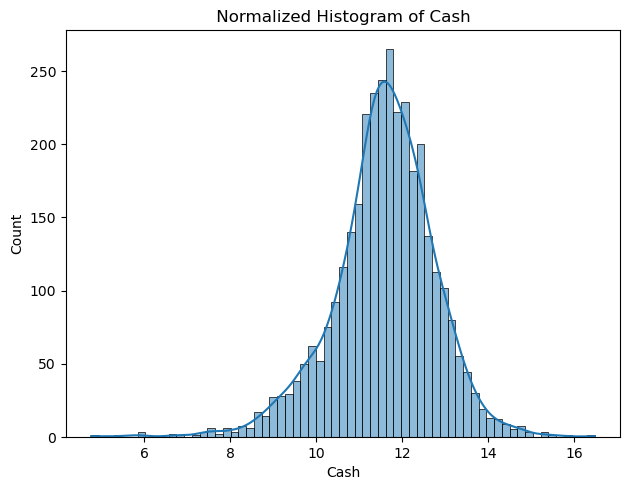

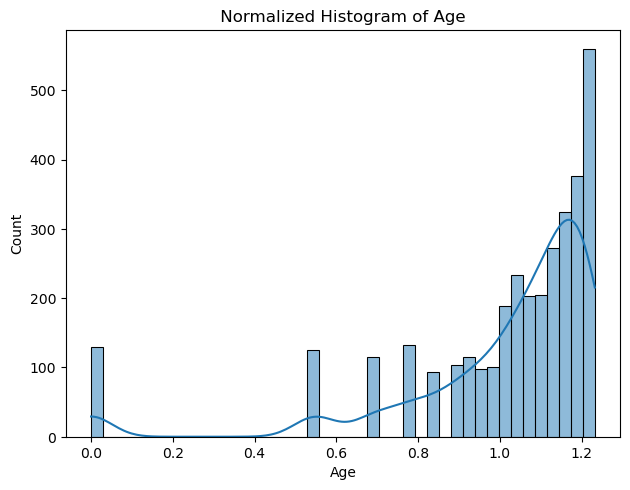

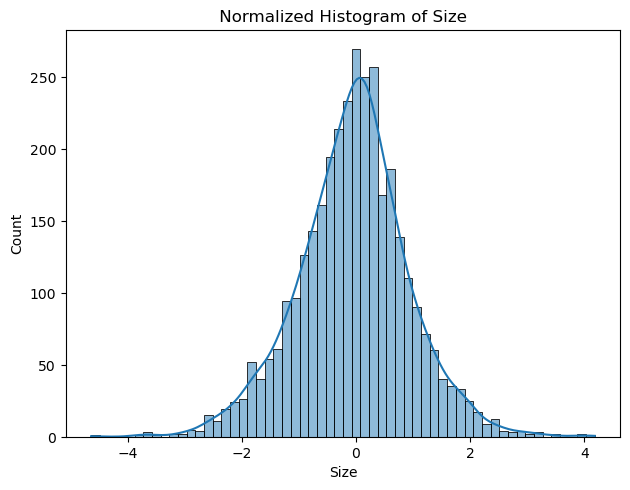

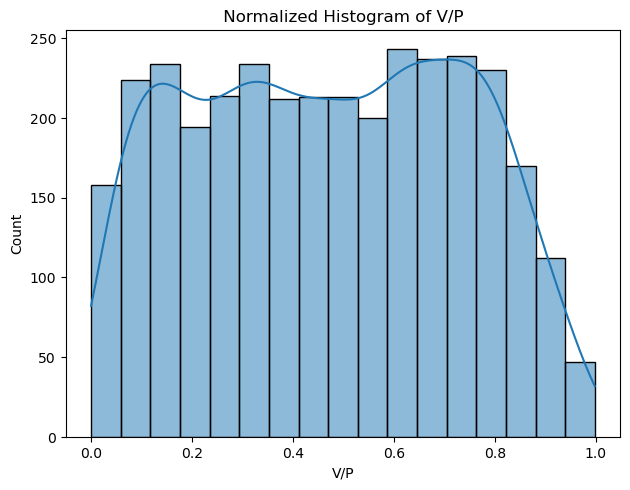

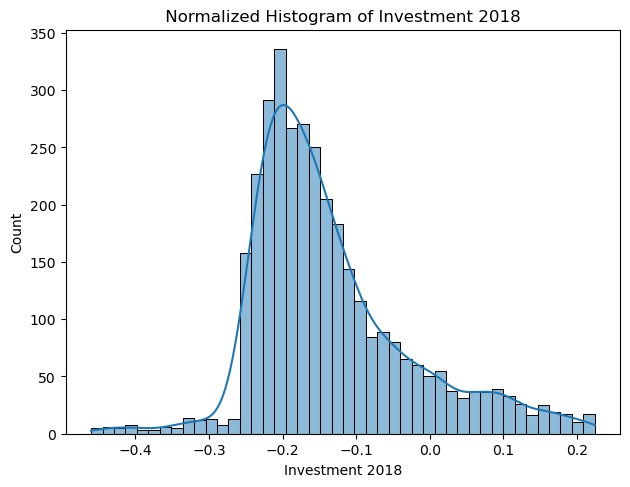

In [3070]:
# Plotting more histograms/ distribution plots after removing outliers to see the effect on different features, how removing outliers affects the shape of their histogram
import seaborn as sns
import matplotlib.pyplot as plt

for feature in df.columns:
    sns.histplot(df[feature], kde=True)
    plt.tight_layout()
    plt.title(f' Normalized Histogram of {feature} ' )
    plt.show()

In [3071]:
# Question 3 A
# Descriptive Statistic summary
df.describe()

#3b - Distribution plots are done previously to help with areas of the project

,Stock Code,Market Value of Equity,Total Market Value,Stock Return,Total Investment Expenditure,Amortization and Depreciation,Book Value,Operating Income after Depreciation,Annual Dividends,Leverage,Cash,Age,Size,V/P,Investment 2018
count,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000,3374.000000
mean,317371.705394,14.946281,15.332162,-0.010520,10.679270,10.093035,13.903327,12.391483,10.835564,0.501922,11.576951,1.010104,-0.050909,0.469328,-0.135493
std,271872.805908,0.931590,0.899724,1.017148,0.963592,0.966899,1.013553,1.023576,1.032658,0.291159,1.175343,0.262954,0.968971,0.262121,0.108488
min,4.000000,10.091154,10.091154,-13.232267,5.986759,5.181494,8.481716,6.857029,5.206769,0.000000,4.758245,0.000000,-4.637513,0.000000,-0.460345
25%,2540.250000,14.395099,14.807522,-0.452373,10.100034,9.504610,13.256416,11.757810,10.187424,0.250682,10.956174,0.950310,-0.624018,0.243411,-0.208473
50%,300452.500000,14.947739,15.269022,-0.108143,10.702397,10.096178,13.919368,12.414736,10.840923,0.494985,11.631502,1.097324,-0.015292,0.471694,-0.162498
75%,600762.750000,15.539620,15.848428,0.384963,11.320596,10.705614,14.573304,13.059444,11.492840,0.758272,12.321572,1.174824,0.535266,0.693916,-0.089312
max,900957.000000,18.324087,19.790178,6.854840,13.555366,13.381208,17.726250,16.214393,14.558911,1.000000,16.478913,1.232280,4.181382,0.998258,0.224113


In [3072]:
# Start of Section 4

#    Define investment_data  dataset
investment_2019 = pd.read_csv('investment_2019.csv') 

# merge your normalized dataset with investment data for starting regression
merged_data = pd.merge(df, investment_data)


In [3073]:
merged_data.head()

,Stock Code,Market Value of Equity,Total Market Value,Stock Return,Total Investment Expenditure,Amortization and Depreciation,Book Value,Operating Income after Depreciation,Annual Dividends,Leverage,Cash,Age,Size,V/P,Investment 2018,Investment2019
0,900939,10.968060,11.691979,0.154214,6.601907,6.271323,9.828626,8.193870,6.642701,0.562269,7.654393,1.109256,0.612404,0.334112,-0.256867,NaN
1,900956,11.939369,12.654022,-0.003057,7.573216,7.156865,11.226019,9.442228,8.121721,0.542469,8.000712,0.000000,2.622636,0.621714,-0.253659,426.652254
2,900952,11.136406,11.136406,-0.050133,7.107849,6.041029,10.463061,9.012761,7.122286,0.485717,5.419538,0.000000,0.734855,0.738349,-0.252751,NaN
3,900933,14.238169,14.238169,-0.032021,10.115425,9.581706,13.394199,11.784761,10.175323,0.266834,11.334834,0.690740,1.198547,0.545639,-0.203820,14590.061900
4,900957,11.535704,12.175840,-0.268697,7.169551,6.930534,10.668203,9.135727,7.309376,0.547267,7.620412,1.221213,-0.390697,0.542998,-0.256347,NaN


Average Adjusted R²: 0.5004051368708695

Saved predictions to 'new_investment_2019.csv'


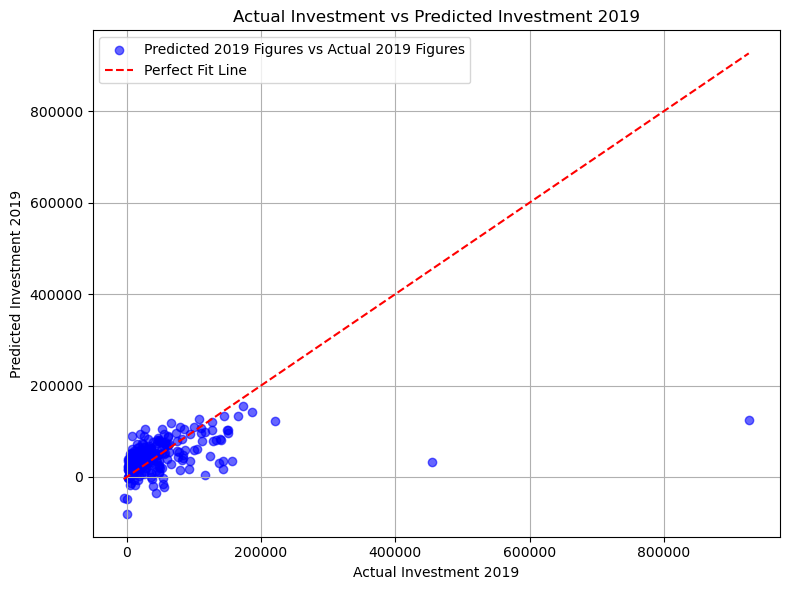

In [3074]:
#Section 4
#Importing the neccesary libraries
from sklearn.model_selection import cross_val_score, KFold, train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.feature_selection import RFE
import pandas as pd
import numpy as np

# Define features being used for calculation
investment_2019 = pd.read_csv('investment_2019.csv')
features1 = ["V/P","Leverage ", "Cash", "Age", "Size", "Stock Return", "Investment 2018"]

# Remove rows with missing target values
merged_data = merged_data.dropna(subset=['Investment2019'])

X = merged_data[features1]
Y = merged_data["Investment2019"]

# Feature Selection using RFE
model = LinearRegression()
rfe = RFE(model, n_features_to_select=5)
X_rfe = rfe.fit_transform(X, Y)

# 10-Fold Cross-Validation
kf = KFold(n_splits=10, shuffle=True, random_state=42)
adjusted_r2_scores = []

# Training the data
for train_index, test_index in kf.split(X_rfe):
    X_train_cv, X_test_cv = X_rfe[train_index], X_rfe[test_index]
y_train_cv, y_test_cv = Y.iloc[train_index], Y.iloc[test_index]

model.fit(X_train_cv, y_train_cv)
y_pred_cv = model.predict(X_test_cv)

r2_cv = r2_score(y_test_cv, y_pred_cv)
n_cv = len(y_test_cv)
k_cv = X_test_cv.shape[1]
adjusted_r2_cv = 1 - (1 - r2_cv) * (n_cv - 1) / (n_cv - k_cv - 1)

adjusted_r2_scores.append(adjusted_r2_cv)

# Calculate the average adjusted R² score
average_adjusted_r2 = np.mean(adjusted_r2_scores)


# Final model evaluation on the test set
X_train, X_test, y_train, y_test = train_test_split(X_rfe, Y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
r2 = r2_score(y_test, Predicted_Investment_2019)
n = len(y_test)
k = X_test.shape[1]
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)

print(f'Average Adjusted R²: {average_adjusted_r2}')


# Save predictions to new dataset
merged_data['Predicted_Investment_2019'] = np.nan
merged_data.loc[merged_data.index, 'Predicted_Investment_2019'] = model.predict(X_rfe)
merged_data[['Stock Code', 'Investment2019', 'Predicted_Investment_2019']].to_csv("new_investment_2019.csv", index=False)
print("\nSaved predictions to 'new_investment_2019.csv'")

# Plot best model for actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Predicted 2019 Figures vs Actual 2019 Figures')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect Fit Line')
plt.xlabel("Actual Investment 2019")
plt.ylabel("Predicted Investment 2019")
plt.title("Actual Investment vs Predicted Investment 2019")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
